This notebook reproduces the Methods section *PPI clustering* and the Results section
*Pace-state clustering*: Supplementary Table S3 (clustering-method comparison), Figure 3
(pace states), Table 2 (pace-state profile and per-feature cut-points) and Figure 4 (EURO 2024
final case example). §4 (boundary bootstrap) gives the CI reported in the text; its figure is
not in the manuscript.

**Input**: `../data/ppi-features.h5`; §6 also reads the EURO 2024 final events from
`../data/men-statsbomb.h5` (read-only).
**Output**: key `pace_states` in the same file.

In [1]:
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import FuncFormatter, MultipleLocator
import seaborn as sns
from sklearn.base import BaseEstimator, ClusterMixin
from sklearn.cluster import KMeans
from sklearn.metrics import (adjusted_rand_score, calinski_harabasz_score,
                             davies_bouldin_score, roc_curve, silhouette_score)
from sklearn.mixture import GaussianMixture
from sklearn.model_selection import GroupShuffleSplit

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)

DATA_DIR = "../data"
FIG_DIR = "../figures"
PPI_H5 = os.path.join(DATA_DIR, "ppi-features.h5")
os.makedirs(FIG_DIR, exist_ok=True)

ppi = pd.read_hdf(PPI_H5, "ppi")
ITEMS = list(pd.read_hdf(PPI_H5, "horst_weights").index)
X = ppi[["PPI"]].to_numpy()
print(f"{len(ppi):,} possessions")

39,995 possessions


## 1 · Clustering-method comparison (Supplementary Table S3)

K-means, K-medians and a Gaussian mixture model (GMM) are fitted to the one-dimensional PPI for
K = 2–8 and the number of states is chosen by the silhouette score (the GMM BIC is reported for
information). At the selected K the three methods are compared in 30 repeated 80/20 holdouts
grouped by match (held-out silhouette, Calinski–Harabasz, Davies–Bouldin, label stability as ARI
against the full-sample solution). Eligible solutions need a mean ARI ≥ 0.90, a smallest cluster
≥ 5 % and exactly K − 1 boundaries on the PPI axis (contiguous, ordered states); among them the
lowest mean rank is selected.

In [2]:
class KMedians1D(BaseEstimator, ClusterMixin):
    """1-D K-medians (L1 objective) with multiple starts."""

    def __init__(self, n_clusters=3, max_iter=300, n_init=20, random_state=42):
        self.n_clusters, self.max_iter = n_clusters, max_iter
        self.n_init, self.random_state = n_init, random_state

    def fit(self, X, y=None):
        x = np.asarray(X, dtype=float).ravel()
        rng = np.random.default_rng(self.random_state)
        best_loss, best_centers, best_labels = np.inf, None, None
        for init in range(self.n_init):
            centers = (np.quantile(x, (np.arange(self.n_clusters) + 0.5) / self.n_clusters)
                       if init == 0 else np.sort(rng.choice(x, size=self.n_clusters, replace=False)))
            for _ in range(self.max_iter):
                dist = np.abs(x[:, None] - centers[None, :])
                labels = dist.argmin(axis=1)
                new = centers.copy()
                for k in range(self.n_clusters):
                    new[k] = (np.median(x[labels == k]) if np.any(labels == k)
                              else x[np.argmax(dist.min(axis=1))])
                new.sort()
                if np.allclose(centers, new, rtol=0, atol=1e-10):
                    break
                centers = new
            labels = np.abs(x[:, None] - centers[None, :]).argmin(axis=1)
            loss = np.abs(x - centers[labels]).sum()
            if loss < best_loss:
                best_loss, best_centers, best_labels = loss, centers.copy(), labels.copy()
        self.cluster_centers_ = best_centers.reshape(-1, 1)
        self.labels_, self.inertia_ = best_labels, best_loss
        return self

    def predict(self, X):
        x = np.asarray(X, dtype=float).ravel()
        return np.abs(x[:, None] - self.cluster_centers_.ravel()[None, :]).argmin(axis=1)


METHODS = ("kmeans", "gmm", "kmedians")
METHOD_LABELS = {"kmeans": "K-means", "gmm": "GMM", "kmedians": "K-medians"}
K_RANGE = range(2, 9)
RANDOM_STATE = 2025


def make_clusterer(method, k, seed=RANDOM_STATE):
    if method == "kmeans":
        return KMeans(n_clusters=k, random_state=seed, n_init=20)
    if method == "gmm":
        return GaussianMixture(n_components=k, covariance_type="full", random_state=seed,
                               n_init=10, reg_covar=1e-6)
    return KMedians1D(n_clusters=k, n_init=20, random_state=seed)


def decision_boundaries(model):
    """PPI values at which the predicted state changes (fine grid over P0.1–P99.9)."""
    lo, hi = np.quantile(X, [0.001, 0.999])
    grid = np.linspace(lo, hi, 30_001).reshape(-1, 1)
    cuts = np.flatnonzero(np.diff(model.predict(grid)) != 0)
    return ((grid[cuts, 0] + grid[cuts + 1, 0]) / 2).tolist()


def central_boundary(model, method):
    centres = np.sort((model.means_ if method == "gmm" else model.cluster_centers_).ravel())
    cuts = decision_boundaries(model)
    return np.nan if not cuts else min(cuts, key=lambda b: abs(b - centres.mean()))

In [3]:
# ── Stage 1: number of states (silhouette; GMM BIC for information) ──────────
sil = {m: [] for m in METHODS}
bic_gmm = []
full_models = {}
for k in K_RANGE:
    for m in METHODS:
        model = make_clusterer(m, k).fit(X)
        full_models[(m, k)] = model
        sil[m].append(silhouette_score(X, model.predict(X), sample_size=10_000,
                                       random_state=RANDOM_STATE))
        if m == "gmm":
            bic_gmm.append(model.bic(X))

k_sel = pd.DataFrame({METHOD_LABELS[m]: sil[m] for m in METHODS}, index=list(K_RANGE))
k_sel["GMM BIC"] = bic_gmm
k_sel.index.name = "K"
print(k_sel.round(4).to_string())
best_k = {m: k_sel.index[int(np.argmax(sil[m]))] for m in METHODS}
K_OPT = int(pd.Series(list(best_k.values())).mode().iloc[0])
print(f"\nSilhouette-optimal K: {best_k};  GMM BIC-optimal K = {k_sel['GMM BIC'].idxmin()}")
print(f"Selected K = {K_OPT}")

# ── Stage 2: method comparison at K_OPT, 30 match-grouped 80/20 holdouts ───────
rng_eval = np.random.default_rng(RANDOM_STATE)
eval_idx = rng_eval.choice(len(X), size=min(10_000, len(X)), replace=False)
X_eval = X[eval_idx]
reference = {m: full_models[(m, K_OPT)].predict(X_eval) for m in METHODS}

rows = []
splitter = GroupShuffleSplit(n_splits=30, test_size=0.20, random_state=RANDOM_STATE)
for split, (tr, te) in enumerate(splitter.split(X, groups=ppi["game_id"].to_numpy())):
    for m in METHODS:
        model = make_clusterer(m, K_OPT, seed=RANDOM_STATE + split + 1).fit(X[tr])
        lab = model.predict(X[te])
        _, counts = np.unique(lab, return_counts=True)
        rows.append(dict(
            method=m,
            silhouette=silhouette_score(X[te], lab, sample_size=min(3_000, len(te)),
                                        random_state=split),
            calinski_harabasz=calinski_harabasz_score(X[te], lab),
            davies_bouldin=davies_bouldin_score(X[te], lab),
            stability_ari=adjusted_rand_score(reference[m], model.predict(X_eval)),
            min_cluster_share=counts.min() / counts.sum(),
            boundary=central_boundary(model, m)))
validation = pd.DataFrame(rows)

table_s3 = validation.groupby("method").agg(
    silhouette_mean=("silhouette", "mean"), silhouette_sd=("silhouette", "std"),
    calinski_harabasz_mean=("calinski_harabasz", "mean"),
    davies_bouldin_mean=("davies_bouldin", "mean"),
    stability_ari_mean=("stability_ari", "mean"), stability_ari_sd=("stability_ari", "std"),
    min_cluster_share_mean=("min_cluster_share", "mean"),
    boundary_mean=("boundary", "mean"), boundary_sd=("boundary", "std"))
table_s3["mean_rank"] = pd.concat([table_s3["silhouette_mean"].rank(ascending=False),
                                   table_s3["calinski_harabasz_mean"].rank(ascending=False),
                                   table_s3["davies_bouldin_mean"].rank(ascending=True),
                                   table_s3["stability_ari_mean"].rank(ascending=False)],
                                  axis=1).mean(axis=1)
table_s3["boundary_count"] = [len(decision_boundaries(full_models[(m, K_OPT)]))
                              for m in table_s3.index]
table_s3["eligible"] = ((table_s3["stability_ari_mean"] >= 0.90)
                        & (table_s3["min_cluster_share_mean"] >= 0.05)
                        & (table_s3["boundary_count"] == K_OPT - 1))
pool = table_s3[table_s3["eligible"]] if table_s3["eligible"].any() else table_s3
CLUSTERING_METHOD = pool.sort_values(["mean_rank", "silhouette_mean"],
                                     ascending=[True, False]).index[0]

table_s3 = table_s3.rename(index=METHOD_LABELS).sort_values("mean_rank")
print("\n=== Table S3 ===")
print(table_s3.round(4).to_string())
print(f"\nSelected: {METHOD_LABELS[CLUSTERING_METHOD]}, K = {K_OPT}")
table_s3.round(4).to_csv(f"{FIG_DIR}/TableS3_clustering_methods.csv")

   K-means     GMM  K-medians      GMM BIC
K                                         
2   0.5639  0.6086     0.5158  108199.0629
3   0.5211  0.5153     0.5002  108263.3372
4   0.5230  0.5115     0.4980  108049.0668
5   0.5192  0.5197     0.4936  108083.7282
6   0.5245  0.5245     0.5059  108119.8718
7   0.5206  0.5234     0.5154  108090.1564
8   0.5195  0.5193     0.5157  108142.4427

Silhouette-optimal K: {'kmeans': 2, 'gmm': 2, 'kmedians': 2};  GMM BIC-optimal K = 4
Selected K = 2



=== Table S3 ===
           silhouette_mean  silhouette_sd  calinski_harabasz_mean  davies_bouldin_mean  stability_ari_mean  stability_ari_sd  min_cluster_share_mean  boundary_mean  boundary_sd  mean_rank  boundary_count  eligible
method                                                                                                                                                                                                               
GMM                 0.6142         0.0078               6309.4807               0.6343              0.9890            0.0055                  0.1213         1.1068       0.0093        1.5               2     False
K-means             0.5612         0.0068              10642.6108               0.6448              0.9741            0.0216                  0.2755         0.3782       0.0214        2.0               1      True
K-medians           0.5139         0.0061               9845.7710               0.6906              0.9862            0.0125  

## 2 · Final pace states

The selected K-means solution (K = 2) is refitted on all possessions; state 0 = low pace,
state 1 = high pace. In one dimension the decision boundary is the midpoint of the two centres.

In [4]:
assert (CLUSTERING_METHOD, K_OPT) == ("kmeans", 2), "the cells below assume the K-means K = 2 solution"

km = KMeans(n_clusters=K_OPT, random_state=42, n_init=20).fit(X)
order = np.argsort(km.cluster_centers_.ravel())
ppi["state"] = np.argsort(order)[km.labels_]                     # 0 = low, 1 = high
centres = km.cluster_centers_.ravel()[order]
shares = np.bincount(ppi["state"]) / len(ppi)
boundary = centres.mean()
STATE_NAMES = {0: "Low", 1: "High"}

print(f"Centres: {centres.round(3)}   boundary PPI = {boundary:+.4f}")
print(ppi.groupby("state")["PPI"].agg(n="size", mean="mean", sd="std")
      .assign(pct=100 * shares).rename(index=STATE_NAMES).round(3).to_string())
for by in ["sex", "tournament"]:
    print(f"\n% of possessions per state by {by}:")
    print((pd.crosstab(ppi[by], ppi["state"], normalize="index") * 100)
          .rename(columns=STATE_NAMES).round(1).to_string())

Centres: [-0.458  1.241]   boundary PPI = +0.3916
           n   mean     sd     pct
state                             
Low    29164 -0.459  0.578  72.919
High   10831  1.237  0.833  27.081

% of possessions per state by sex:


state   Low  High
sex              
Men    69.9  30.1
Women  76.5  23.5

% of possessions per state by tournament:
state        Low  High
tournament            
EURO2020    69.9  30.1
EURO2024    70.4  29.6
WC2022      69.6  30.4
WEURO2022   75.5  24.5
WEURO2025   76.3  23.7
WWC2023     77.1  22.9


## 3 · Figure 3 — pace states

(a) PPI distribution of the low- and high-pace states with state centres (dashed) and the decision
boundary (dotted); (b) state composition by tournament (chronological).

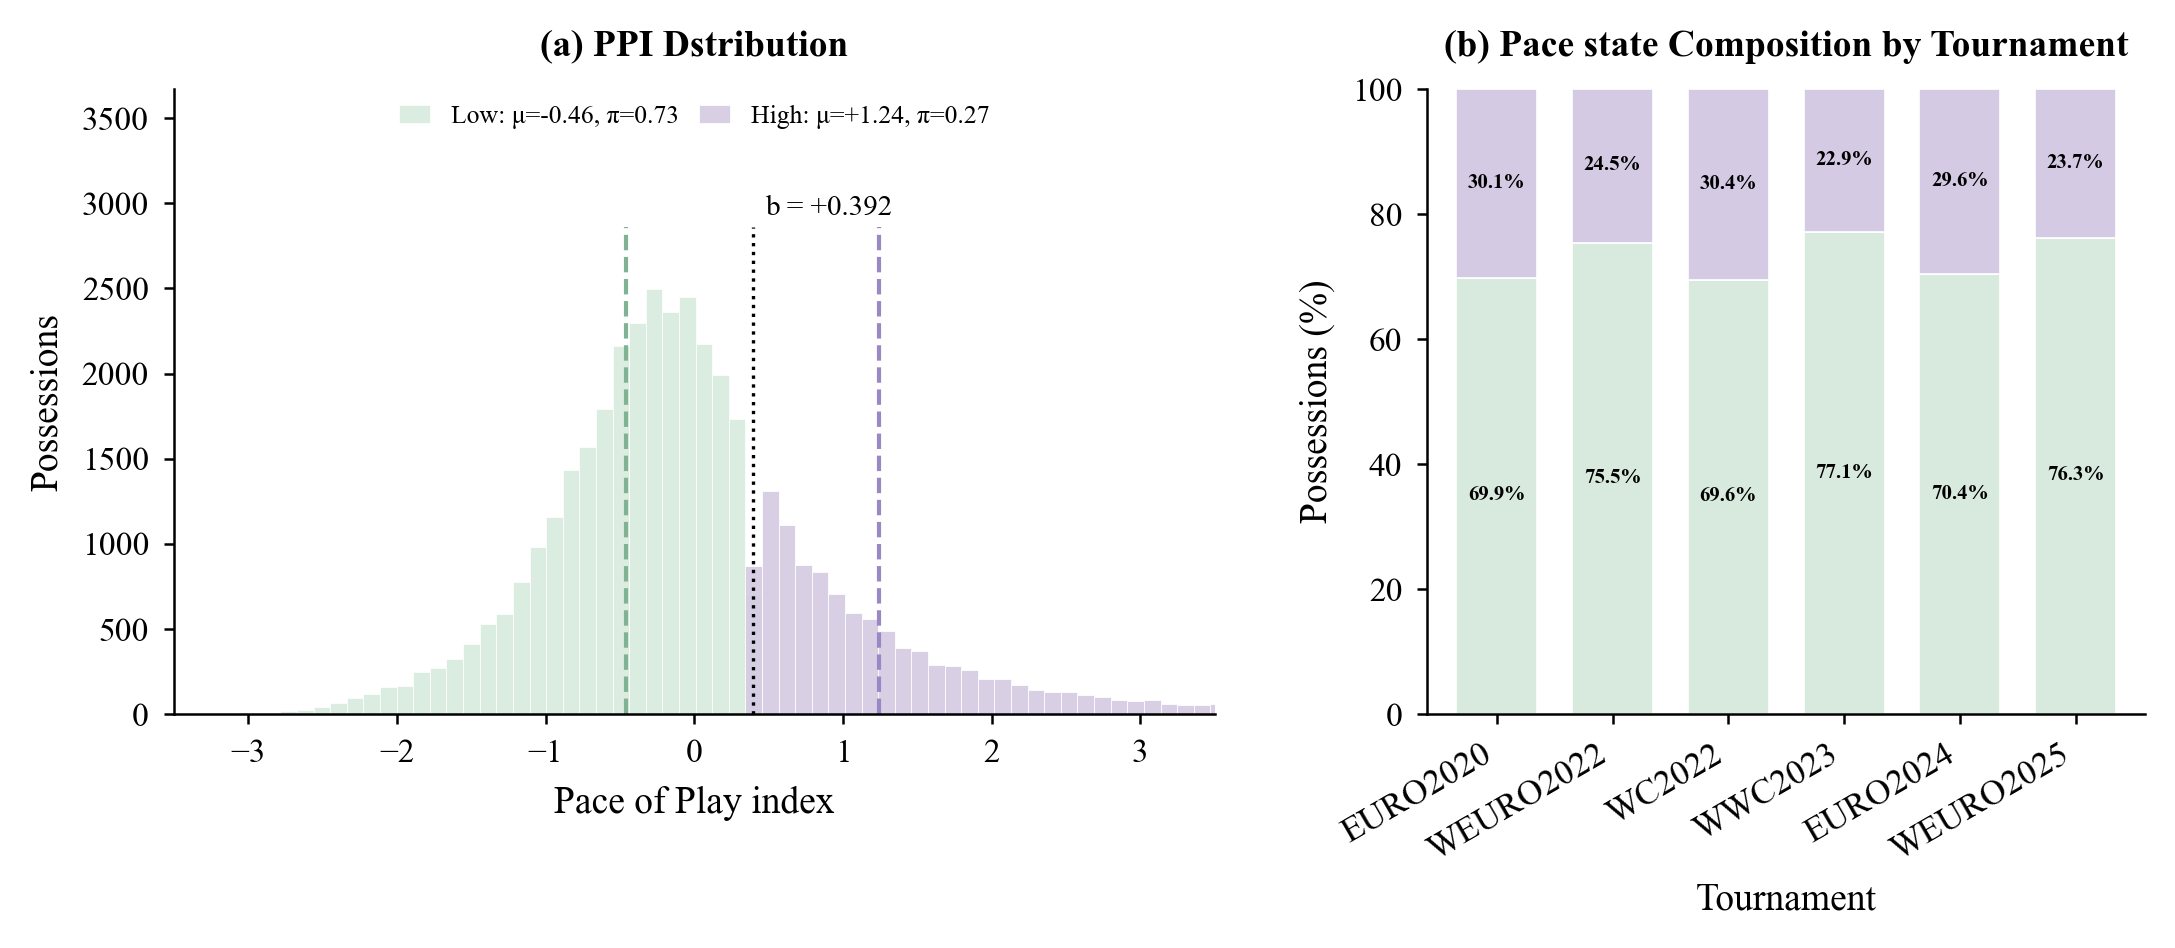

In [5]:
plt.rcParams.update({
    "font.family": "serif", "font.serif": ["Times New Roman"], "font.size": 9,
    "axes.titlesize": 10, "axes.labelsize": 9, "xtick.labelsize": 8, "ytick.labelsize": 8,
    "legend.fontsize": 8, "axes.linewidth": 0.6, "xtick.major.width": 0.6,
    "ytick.major.width": 0.6, "xtick.major.size": 2.5, "ytick.major.size": 2.5,
    "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False,
    "savefig.dpi": 300, "figure.dpi": 300,
})
STATE_COLOURS = ["#d8eade", "#d5cae3"]
CENTRE_COLOURS = ["#7fb394", "#9a88c4"]
TOURN_TIMELINE = ["EURO2020", "WEURO2022", "WC2022", "WWC2023", "EURO2024", "WEURO2025"]

v, s = ppi["PPI"].to_numpy(), ppi["state"].to_numpy()
fig, ax = plt.subplots(1, 2, figsize=(7.09, 3.0), constrained_layout=True,
                       gridspec_kw={"width_ratios": [1.45, 1]})
fig.set_constrained_layout_pads(w_pad=0.02, h_pad=0.02, wspace=0.08)

a = ax[0]
bins = np.linspace(v.min(), v.max(), 80)
for k in range(K_OPT):
    a.hist(v[s == k], bins=bins, color=STATE_COLOURS[k], alpha=0.9, edgecolor="white",
           linewidth=0.2, label=f"{STATE_NAMES[k]}: μ={centres[k]:+.2f}, π={shares[k]:.2f}")
    a.axvline(centres[k], ymax=0.78, color=CENTRE_COLOURS[k], ls="--", lw=1.0)
a.set_xlim(-3.5, 3.5)
a.set_ylim(0, a.get_ylim()[1] * 1.40)
a.axvline(boundary, ymax=0.78, color="black", ls=":", lw=0.8)
a.annotate(f"b = {boundary:+.3f}", xy=(boundary, a.get_ylim()[1] * 0.81), xytext=(3, 0),
           textcoords="offset points", fontsize=7, ha="left", va="center",
           bbox=dict(facecolor="white", edgecolor="none", pad=1, alpha=0.85))
a.set_xlabel("Pace of Play index")
a.set_ylabel("Possessions")
a.legend(loc="upper center", ncol=2, fontsize=6.2, handlelength=1.2, columnspacing=0.8,
         borderaxespad=0.2)
a.set_title("(a) PPI Dstribution", fontsize=9, fontweight="bold", pad=8)

b = ax[1]
comp = (pd.crosstab(ppi["tournament"], ppi["state"], normalize="index") * 100)
comp = comp.rename(columns=STATE_NAMES).loc[TOURN_TIMELINE]
comp.plot(kind="bar", stacked=True, color=STATE_COLOURS, ax=b, width=0.7, edgecolor="white",
          linewidth=0.4, legend=False)
for c in b.containers:
    b.bar_label(c, label_type="center", fmt="%.1f%%", fontsize=5, color="black",
                fontweight="bold")
b.set_xlabel("Tournament")
b.set_ylabel("Possessions (%)")
b.set_ylim(0, 100)
b.tick_params(axis="x", rotation=30, labelsize=8.5)
for lbl in b.get_xticklabels():
    lbl.set_horizontalalignment("right")
b.set_title("(b) Pace state Composition by Tournament", fontsize=9, fontweight="bold", pad=8)

fig.savefig(f"{FIG_DIR}/Figure3_pace_states.png", dpi=300, bbox_inches="tight")
plt.show()

## 4 · Stability of the state boundary (CI reported in the text; figure not in the manuscript)

Matches are resampled with replacement (B = 2,000) and the K = 2 boundary is re-estimated in each
replicate. For speed, each replicate uses the exact one-dimensional 2-means optimum (scan of all
contiguous splits; boundary = midpoint of the two means).

K-means boundary +0.392  (exact 2-means optimum on the full sample +0.376)
Match bootstrap (B = 2000, 292 matches): 95% CI [+0.332, +0.421], SD = 0.023
Possessions within the CI: 3.2%


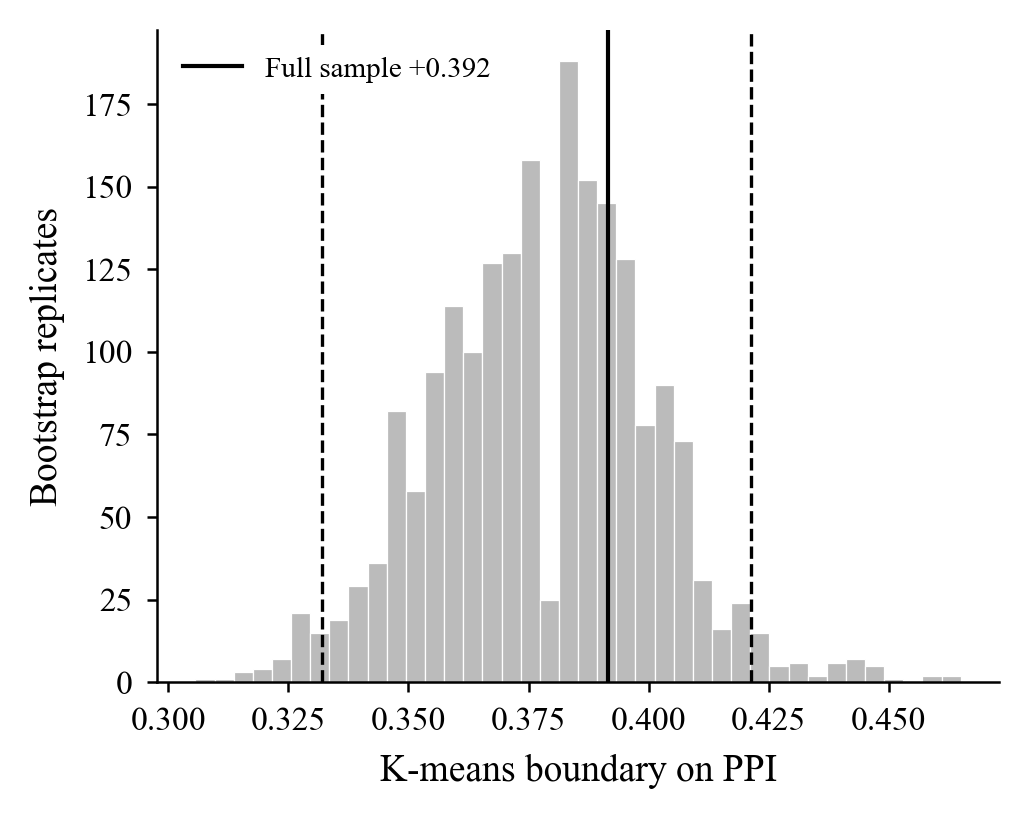

In [6]:
def two_means_boundary(x):
    xs = np.sort(np.asarray(x, dtype=float))
    n = len(xs)
    cs, cs2 = np.cumsum(xs), np.cumsum(xs ** 2)
    n_left = np.arange(1, n)
    s_l, s2_l = cs[:-1], cs2[:-1]
    s_r, s2_r = cs[-1] - s_l, cs2[-1] - s2_l
    sse = (s2_l - s_l ** 2 / n_left) + (s2_r - s_r ** 2 / (n - n_left))
    j = int(np.argmin(sse))
    return (s_l[j] / n_left[j] + s_r[j] / (n - n_left[j])) / 2


by_match = [g.to_numpy() for _, g in ppi.groupby("game_id")["PPI"]]
rng = np.random.default_rng(2025)
boot_b = np.array([two_means_boundary(np.concatenate(
    [by_match[i] for i in rng.integers(0, len(by_match), len(by_match))])) for _ in range(2000)])
b_lo, b_hi = np.quantile(boot_b, [0.025, 0.975])

print(f"K-means boundary {boundary:+.3f}  (exact 2-means optimum on the full sample "
      f"{two_means_boundary(v):+.3f})")
print(f"Match bootstrap (B = 2000, {len(by_match)} matches): 95% CI [{b_lo:+.3f}, {b_hi:+.3f}], "
      f"SD = {boot_b.std():.3f}")
print(f"Possessions within the CI: {ppi['PPI'].between(b_lo, b_hi).mean():.1%}")

fig, a = plt.subplots(figsize=(3.5, 2.8))
a.hist(boot_b, bins=40, color="#BBBBBB", edgecolor="white", linewidth=0.3)
a.axvline(boundary, color="black", lw=1.0, label=f"Full sample {boundary:+.3f}")
for q in (b_lo, b_hi):
    a.axvline(q, color="black", lw=0.8, ls="--")
a.set_xlabel("K-means boundary on PPI")
a.set_ylabel("Bootstrap replicates")
a.legend(loc="upper left", fontsize=7, frameon=True, facecolor="white", edgecolor="none",
         framealpha=1)
sns.despine(ax=a)
plt.tight_layout()
fig.savefig(f"{FIG_DIR}/boundary_bootstrap.png", dpi=300, bbox_inches="tight")
plt.show()

## 5 · Pace-state profile and per-feature cut-points (Table 2)

The nine PPI variables (winsorised, natural units) are summarised per state as mean ± SD, with
Cohen's d = (high − low) / pooled SD. For each variable the Youden's-J-optimal cut-point of a ROC
curve against the state assignment gives a single-variable high-pace rule, with its sensitivity,
specificity, accuracy and balanced accuracy (inter-pass interval: shorter = faster, hence "<").
All values go to `Table2_pace_state_profile.csv`; the rendered table shows the state means, the rule,
the balanced accuracy and Cohen's d (pass `stats=` to show other columns).

In [7]:
LABELS = {
    "passes_per_minute": "Passes per minute",
    "distance_per_second": "Ball displacement per second",
    "distance_per_touch": "Ball displacement per touch",
    "time_to_pass": "Inter-pass interval",
    "spatial_compression_x": "Longitudinal spatial spread",
    "spatial_compression_y": "Lateral spatial spread",
    "goal_directed_displacement_per_second": "Goal-directed ball displacement per second",
    "progressive_action_rate": "Progressive action rate",
    "opponents_bypassed_per_second": "Opponents bypassed per second",
}
INVERT = {"time_to_pass"}                       # shorter interval = faster play
state = ppi["state"].to_numpy()
low, high = ppi[state == 0], ppi[state == 1]


def cohen_d(a, b):
    sp = np.sqrt(((len(a) - 1) * a.var() + (len(b) - 1) * b.var()) / (len(a) + len(b) - 2))
    return (b.mean() - a.mean()) / sp


def youden_rule(x, y, invert=False):
    """Youden's-J-optimal cut-point of x for the high-pace state."""
    score = -x if invert else x                 # higher score = faster
    fpr, tpr, thr = roc_curve(y, score)
    j = int(np.argmax(tpr - fpr))
    return dict(rule="<" if invert else ">", cut=-thr[j] if invert else thr[j],
                sensitivity=tpr[j], specificity=1 - fpr[j],
                accuracy=((score >= thr[j]) == y).mean(),
                balanced_accuracy=(tpr[j] + 1 - fpr[j]) / 2)


profile = pd.DataFrame([
    dict(variable=LABELS[f],
         low_mean=low[f].mean(), low_sd=low[f].std(),
         high_mean=high[f].mean(), high_sd=high[f].std(),
         cohen_d=cohen_d(low[f], high[f]),
         **youden_rule(ppi[f].to_numpy(), state, invert=f in INVERT))
    for f in ITEMS])
print(f"Low pace n = {len(low):,}, high pace n = {len(high):,}")
print(profile.round(3).to_string(index=False))
profile.round(4).to_csv(f"{FIG_DIR}/Table2_pace_state_profile.csv", index=False)

Low pace n = 29,164, high pace n = 10,831
                                  variable  low_mean  low_sd  high_mean  high_sd  cohen_d rule    cut  sensitivity  specificity  accuracy  balanced_accuracy
                         Passes per minute    17.489   5.985     25.296    8.629    1.148    > 21.111        0.648        0.783     0.747              0.716
              Ball displacement per second     7.481   1.973      9.524    2.513    0.958    >  8.138        0.686        0.705     0.700              0.696
               Ball displacement per touch    12.159   5.377     12.753    6.223    0.106    > 14.974        0.261        0.804     0.657              0.533
                       Inter-pass interval     3.955   1.496      2.845    1.239   -0.776    <  2.970        0.637        0.750     0.719              0.693
               Longitudinal spatial spread     7.714   1.619      8.008    1.747    0.178    >  8.587        0.360        0.721     0.623              0.541
                

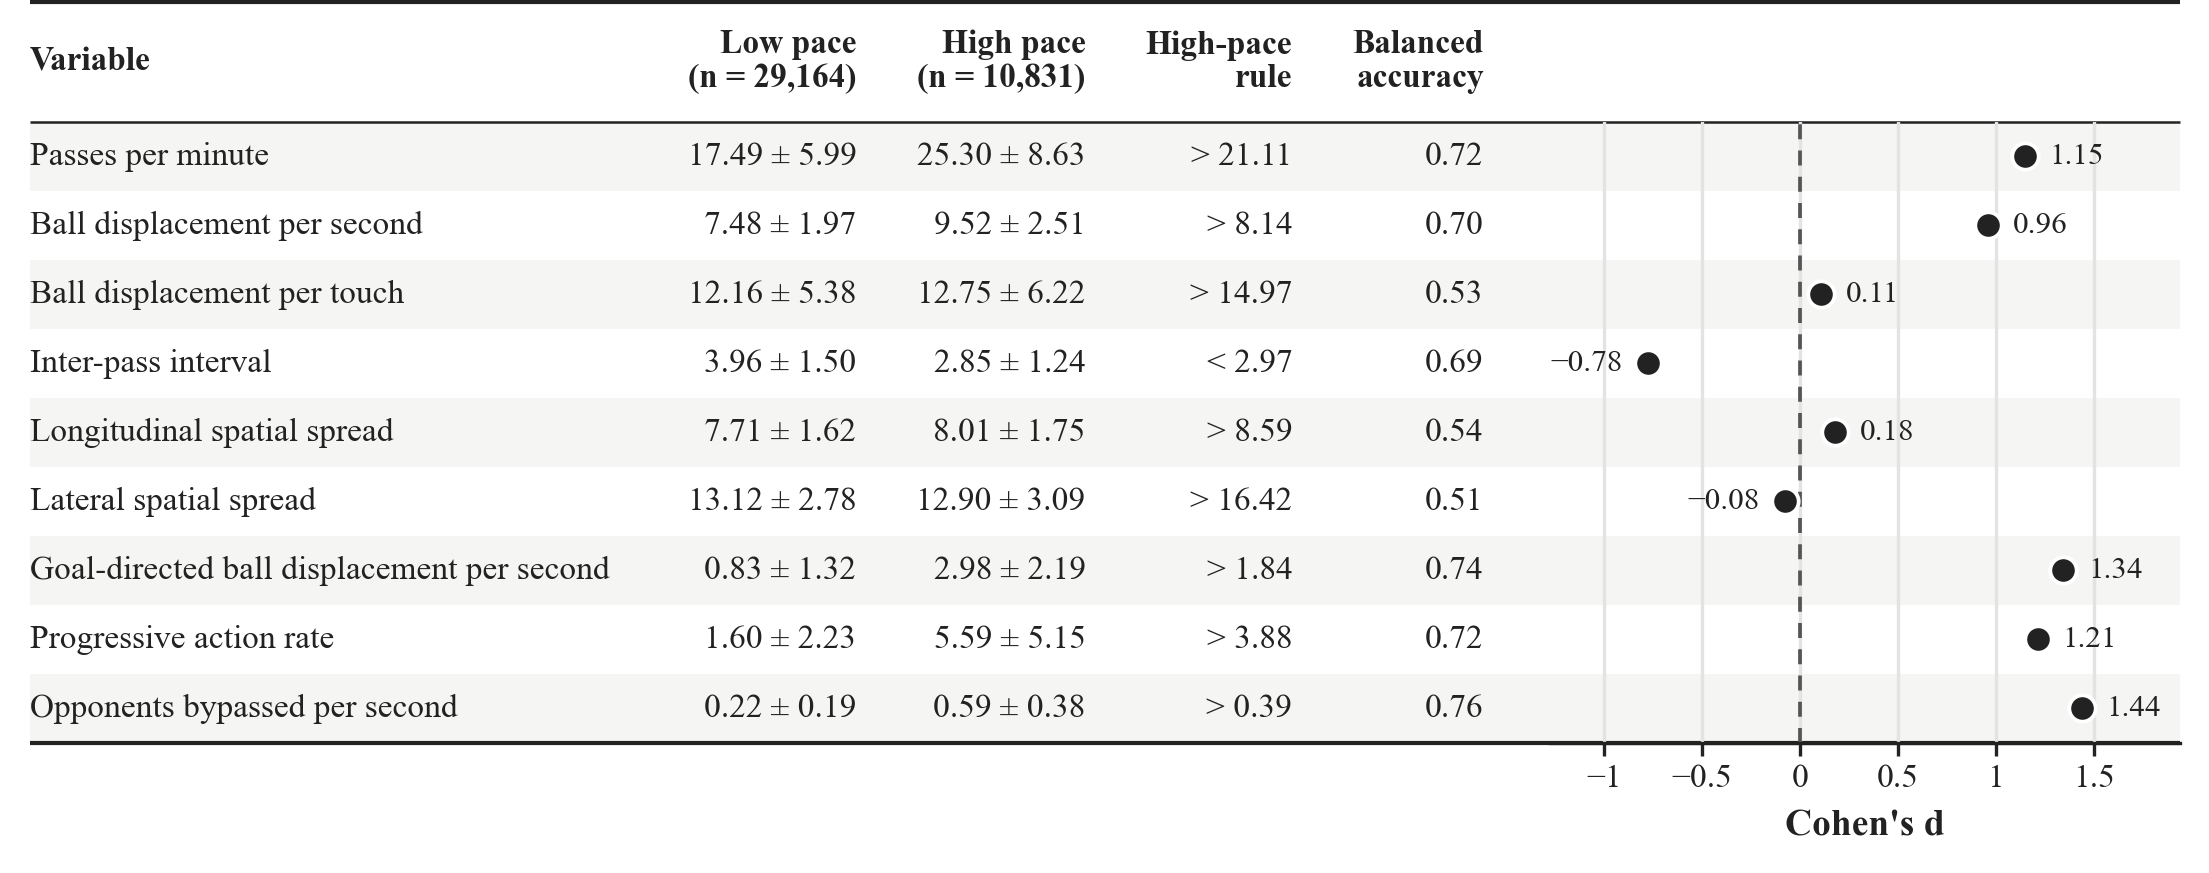

In [8]:
INK, RULE_GREY, ZEBRA, GRID = "#222222", "#555555", "#f5f5f3", "#e3e3e3"
PROFILE_RC = {"font.size": 8, "axes.linewidth": 0.8, "xtick.major.width": 0.8,
              "pdf.fonttype": 42, "svg.fonttype": "none"}
STAT_COLS = {                                   # key -> (header, cell text from a row)
    "rule": ("High-pace\nrule", lambda r: f"{r.rule} {r.cut:.2f}"),
    "sens": ("Sensitivity", lambda r: f"{r.sensitivity:.2f}"),
    "spec": ("Specificity", lambda r: f"{r.specificity:.2f}"),
    "acc": ("Accuracy", lambda r: f"{r.accuracy:.2f}"),
    "ba": ("Balanced\naccuracy", lambda r: f"{r.balanced_accuracy:.2f}"),
}


def minus(s):
    return s.replace("-", "−")


def plot_pace_profile(df, n_low, n_high, stats=("rule", "ba"), title=None, dec=2,
                      forest_w=2.1, xlabel="Cohen's d", zebra=True):
    """Table of state means ± SD and Youden rules (left) + Cohen's d dot plot (right)."""
    n = len(df)
    hdr = dict(fontweight="bold", color=INK)
    ms = lambda m, s: minus(f"{m:.{dec}f} ± {s:.{dec}f}")
    cols = [("Variable", list(df["variable"]), "left"),               # (header, cells, align)
            (f"Low pace\n(n = {n_low:,})", [ms(*v) for v in zip(df.low_mean, df.low_sd)],
             "right"),
            (f"High pace\n(n = {n_high:,})", [ms(*v) for v in zip(df.high_mean, df.high_sd)],
             "right")]
    cols += [(STAT_COLS[k][0], [minus(STAT_COLS[k][1](r)) for r in df.itertuples()], "right")
             for k in stats]

    with plt.rc_context(PROFILE_RC):
        fig = plt.figure()
        renderer = fig.canvas.get_renderer()

        def text_w(s, **kw):                    # rendered width in inches
            t = fig.text(0, 0, s, **kw)
            w = t.get_window_extent(renderer).width / fig.dpi
            t.remove()
            return w

        # ---- layout (inches) from the measured column widths -----------------
        ml, mr, gap_first, gap, gap_forest = 0.05, 0.30, 0.26, 0.20, 0.22
        row_h, head_h, top, bot = 0.23, 0.40, 0.05, 0.48
        title_h = 0.30 if title else 0.0
        spans, x = [], 0.0
        for i, (h, cells, _) in enumerate(cols):
            x += (gap_first if i == 1 else gap) if i else 0
            w = max([text_w(c) for c in cells] + [text_w(h, **hdr)])
            spans.append((x, x + w))
            x += w
        table_w = x
        W, H = ml + table_w + gap_forest + forest_w + mr, top + title_h + head_h + n * row_h + bot
        fig.set_size_inches(W, H)
        axT = fig.add_axes([ml / W, bot / H, table_w / W, n * row_h / H])
        axF = fig.add_axes([(ml + table_w + gap_forest) / W, bot / H, forest_w / W,
                            n * row_h / H])
        for ax in (axT, axF):
            ax.set_ylim(n - 0.5, -0.5)
        axT.set_xlim(0, table_w)
        axT.axis("off")
        right = table_w + gap_forest + forest_w   # table + forest, in axT x units
        head = head_h / row_h                     # header height in row units

        # ---- zebra stripes and three-line rules ------------------------------
        if zebra:
            for i in range(0, n, 2):
                axT.fill_between([0, right], i - 0.5, i + 0.5, color=ZEBRA, lw=0,
                                 zorder=0, clip_on=False)
        for y, lw in ((-0.5 - head, 1.0), (-0.5, 0.6), (n - 0.5, 1.0)):
            axT.plot([0, right], [y, y], color=INK, lw=lw, solid_capstyle="butt",
                     clip_on=False, zorder=3)

        # ---- title (centred over table + forest), header and cells ---------------
        # if title:
        #     axT.text(right / 2, -0.5 - head - 0.10 / row_h, title, ha="center",
        #              va="bottom", fontsize=10, clip_on=False, **hdr)
        header_y = -0.5 - head / 2

        for (h, cells, ha), (x0, x1) in zip(cols, spans):
            xt = x0 if ha == "left" else x1

            axT.text(
                xt, header_y, h,
                ha=ha, va="center",
                linespacing=1.15,
                clip_on=False, **hdr
            )

            for i, c in enumerate(cells):
                axT.text(
                    xt, i, c,
                    ha=ha, va="center",
                    color=INK
                )

        # ---- Cohen's d -------------------------------------------------------
        d = df["cohen_d"].to_numpy()
        axF.patch.set_alpha(0)                    # let the zebra stripes show through
        pad = 0.5                                 # room for the value labels
        axF.set_xlim(min(d.min(), 0) - pad, max(d.max(), 0) + pad)
        axF.xaxis.set_major_locator(MultipleLocator(0.5))
        axF.xaxis.set_major_formatter(FuncFormatter(lambda v, _: minus(f"{v:g}")))
        axF.grid(axis="x", color=GRID, lw=0.8, zorder=1)
        axF.axvline(0, color=RULE_GREY, lw=0.9, ls=(0, (4, 3)), zorder=2)
        axF.scatter(d, np.arange(n), s=40, color=INK, edgecolor="white", linewidth=0.9,
                    zorder=4)
        for i, di in enumerate(d):                # direction = side of the zero line
            pos = di >= 0
            axF.annotate(minus(f"{di:.2f}"), (di, i), xytext=(6 if pos else -6, 0),
                         textcoords="offset points", ha="left" if pos else "right",
                         va="center", color=INK, fontsize=7.5)
        axF.set_xlabel(xlabel, fontweight="bold", color=INK, labelpad=4)
        axF.tick_params(axis="x", length=3, colors=INK, pad=2)
        axF.tick_params(axis="y", left=False, labelleft=False)
        for s in ("top", "right", "left"):
            axF.spines[s].set_visible(False)
        axF.spines["bottom"].set_color(INK)
    return fig


fig = plot_pace_profile(profile, n_low=len(low), n_high=len(high),
                        )
# other columns: stats=("rule", "sens", "spec", "acc", "ba")
for ext, kw in (("png", dict(dpi=600)), ("pdf", {})):
    fig.savefig(f"{FIG_DIR}/Table2_pace_state_profile.{ext}", **kw)
plt.show()

## 6 · Figure 4 — case example: EURO 2024 final (Spain 2–1 England)

          n  mean
team             
England  30 -0.15
Spain    30  0.26
Spain between the equaliser and the winner: [0.5, -0.34, -0.94, 0.58, -1.22, -0.24, -0.57, -0.46, 0.15]


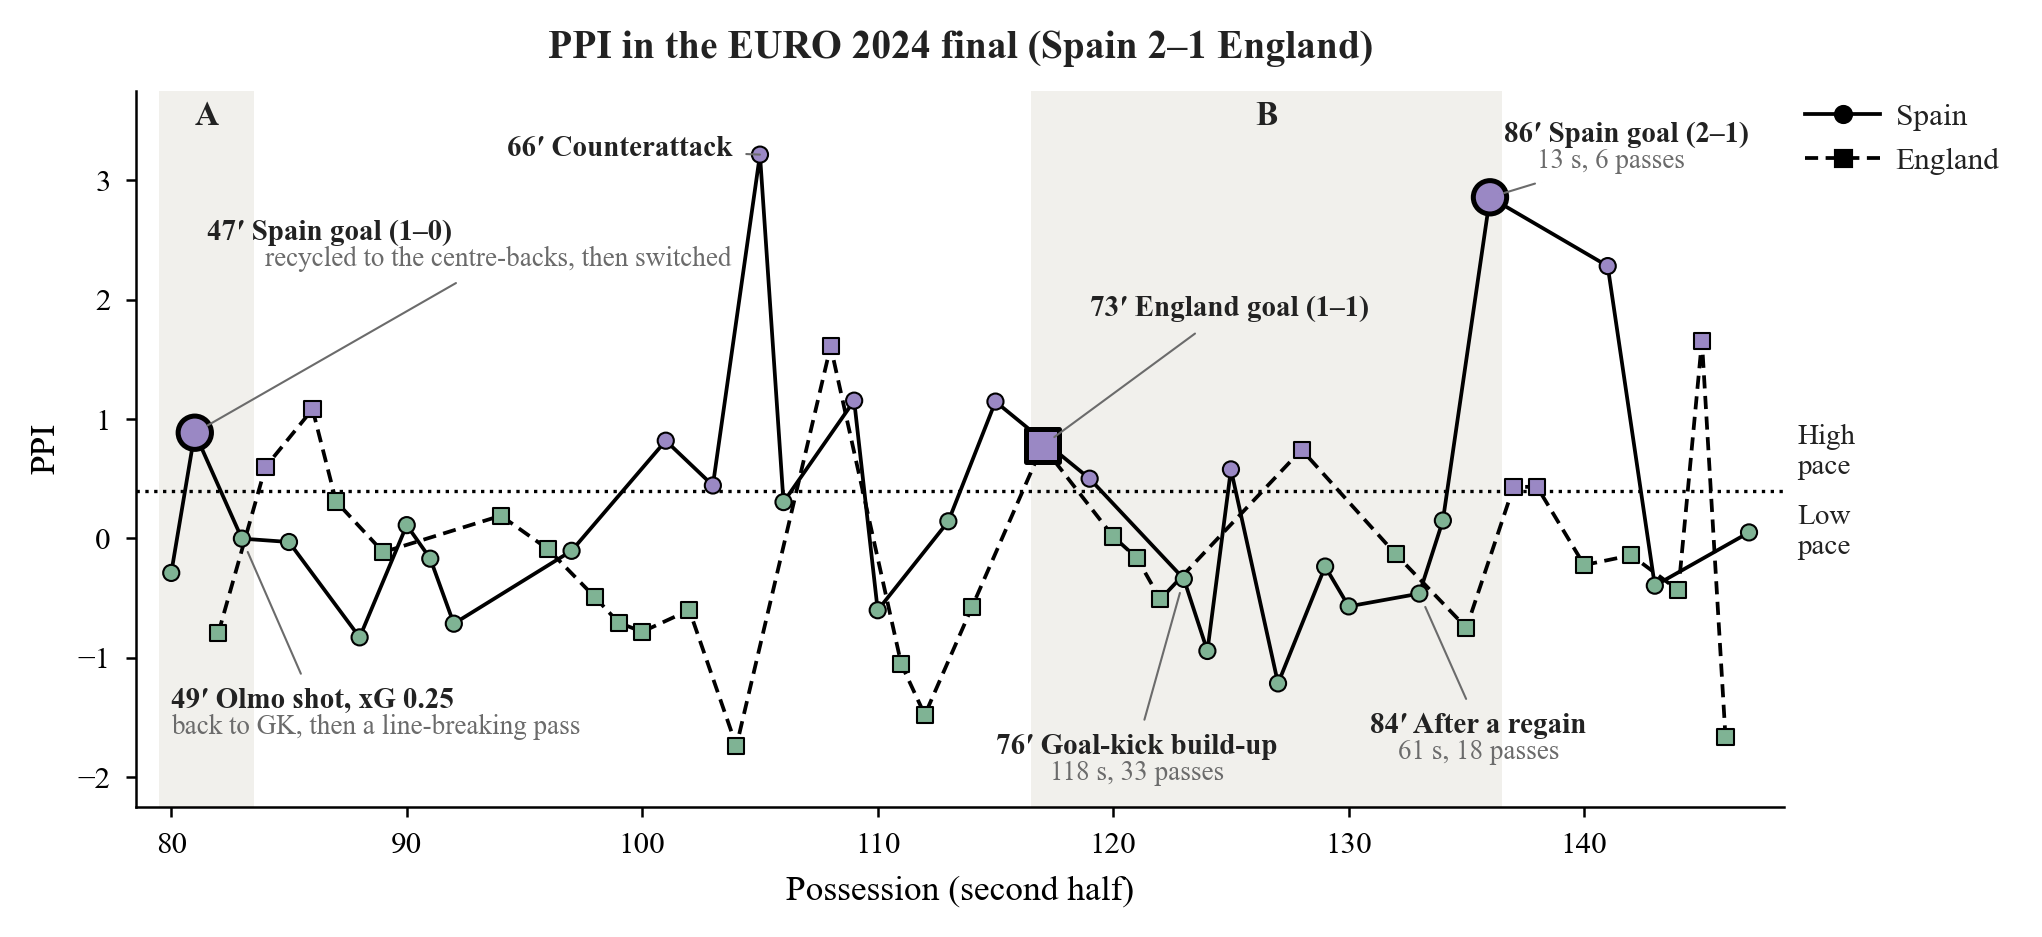

In [9]:
GAME_ID = 3943043                                   # EURO 2024 final, Spain 2–1 England
SEGMENTS = {"A": (80, 83), "B": (117, 136)}         # StatsBomb possession ids
TEAM_STYLE = {"Spain": dict(ls="-", marker="o"), "England": dict(ls=(0, (3.5, 2)), marker="s")}
SEGMENT_SHADE = "#f1f0ec"
CASE_INK, CASE_MUTED = "#222222", "#6b6b6b"
CASE_RC = {"font.family": "serif", "font.serif": ["Times New Roman"], "font.size": 8, "axes.linewidth": 0.6, "xtick.major.width": 0.6,
           "ytick.major.width": 0.6, "xtick.major.size": 2.5, "ytick.major.size": 2.5,
           "xtick.labelsize": 7.5, "ytick.labelsize": 7.5, "axes.labelsize": 8.5,
           "axes.spines.top": False, "axes.spines.right": False,
           "pdf.fonttype": 42, "svg.fonttype": "none"}

# ── possession facts from the raw StatsBomb events 
with pd.HDFStore(os.path.join(DATA_DIR, "men-statsbomb.h5"), "r") as store:
    ev = store[f"events/game_{GAME_ID}"].sort_values("index")
ev["sec"] = ev["timestamp"].dt.total_seconds()
own = ev[ev["team_name"] == ev["possession_team_name"]]
poss = own.groupby("possession").agg(team=("possession_team_name", "first"),
                                     period=("period_id", "first"),
                                     minute=("minute", "first"),
                                     duration=("sec", lambda s: s.max() - s.min()))
poss["n_pass"] = own[own["type_name"] == "Pass"].groupby("possession").size()
poss["n_pass"] = poss["n_pass"].fillna(0).astype(int)
shots = own[own["type_name"] == "Shot"].assign(
    outcome=lambda d: d["extra"].map(lambda e: e["shot"]["outcome"]["name"]),
    xg=lambda d: d["extra"].map(lambda e: e["shot"]["statsbomb_xg"]))
goals = shots[shots["outcome"] == "Goal"].copy()
score = {"Spain": 0, "England": 0}
for i, r in goals.iterrows():
    score[r["team_name"]] += 1
    goals.loc[i, "label"] = f"{r['minute'] + 1}′ {r['team_name']} goal ({score['Spain']}–{score['England']})"
goal_label = goals.set_index("possession")["label"]

case = (ppi.loc[ppi["game_id"] == GAME_ID, ["possession", "PPI", "state"]]
        .join(poss, on="possession"))
case = case[case["period"] == 2].sort_values("possession")
print(case.groupby("team")["PPI"].agg(n="size", mean="mean").round(2).to_string())
print("Spain between the equaliser and the winner:",
      case.query("team == 'Spain' and 117 < possession < 136")["PPI"].round(2).tolist())

# ── annotations: (possession, title, detail, dx, dy, ha) ──────────────────────────────
p = poss.loc
olmo = shots.query("possession == 83").iloc[0]
NOTES = [
    (81, goal_label[81], "recycled to the centre-backs, then switched", 3.0, 1.35, "left"),
    (83, f"{olmo['minute'] + 1}′ Olmo shot, xG {olmo['xg']:.2f}",
     "back to GK, then a line-breaking pass", -3.0, -1.25, "left"),
    (105, f"{p[105, 'minute'] + 1}′ Counterattack", None, -1.2, 0.05, "right"),
    (117, goal_label[117], None, 2.0, 1.15, "left"),
    (123, f"{p[123, 'minute'] + 1}′ Goal-kick build-up",
     f"{p[123, 'duration']:.0f} s, {p[123, 'n_pass']} passes", -2.0, -1.3, "center"),
    (133, f"{p[133, 'minute'] + 1}′ After a regain",
     f"{p[133, 'duration']:.0f} s, {p[133, 'n_pass']} passes", 2.5, -1.0, "center"),
    (136, goal_label[136], f"{p[136, 'duration']:.0f} s, {p[136, 'n_pass']} passes",
     2.0, 0.2, "left"),
]


def case_note(ax, pos, title, detail, dx, dy, ha):
    """Bold title + muted detail line; the leader line attaches to the block edge nearest the point."""
    y = case.loc[case["possession"] == pos, "PPI"].item()
    frac = {"left": 0, "center": 0.5, "right": 1}[ha]
    lead = dict(arrowstyle="-", color=CASE_MUTED, lw=0.5, shrinkA=1.5, shrinkB=3.5)
    t_kw = dict(fontsize=7, fontweight="bold", color=CASE_INK, ha=ha, zorder=6)
    d_kw = dict(fontsize=6.5, color=CASE_MUTED, ha=ha, zorder=6)
    if detail is None:
        ax.annotate(title, (pos, y), (pos + dx, y + dy), va="center", arrowprops=lead, **t_kw)
    elif dy > 0:                       
        d = ax.annotate(detail, (pos, y), (pos + dx, y + dy), va="bottom", arrowprops=lead, **d_kw)
        ax.annotate(title, (frac, 1), xycoords=d, va="bottom", **t_kw)
    else:                             
        t = ax.annotate(title, (pos, y), (pos + dx, y + dy), va="top", arrowprops=lead, **t_kw)
        ax.annotate(detail, (frac, 0), xycoords=t, va="top", **d_kw)


with plt.rc_context(CASE_RC):
    fig, ax = plt.subplots(figsize=(7.09, 3.1))
    y_lo, y_hi = -2.25, 3.75
    for x0, x1 in SEGMENTS.values():
        ax.axvspan(x0 - 0.5, x1 + 0.5, color=SEGMENT_SHADE, lw=0, zorder=0)
    ax.axhline(boundary, color="black", ls=":", lw=0.8, zorder=1)
    tr = ax.get_yaxis_transform()
    for txt, yy, va in [("High\npace", boundary + 0.1, "bottom"), ("Low\npace", boundary - 0.1, "top")]:
        ax.text(1.008, yy, txt, transform=tr, ha="left", va=va, fontsize=7, color=CASE_INK)

    for team, st in TEAM_STYLE.items():           
        g = case[case["team"] == team]
        fill = [CENTRE_COLOURS[k] for k in g["state"]]
        is_goal = g["possession"].isin(goals["possession"]).to_numpy()
        ax.plot(g["possession"], g["PPI"], color="black", lw=0.9, ls=st["ls"], zorder=2)
        ax.scatter(g["possession"], g["PPI"], s=np.where(is_goal, 64, 15), marker=st["marker"],
                   c=fill, edgecolors="black", linewidths=np.where(is_goal, 1.2, 0.5), zorder=3)

    for lab, (x0, x1) in SEGMENTS.items():
        ax.text((x0 + x1) / 2, 0.985, lab, transform=ax.get_xaxis_transform(), ha="center",
                va="top", fontsize=8, fontweight="bold", color=CASE_INK)

    for note in NOTES:
        case_note(ax, *note)

    ax.set_xlim(case["possession"].min() - 1.5, case["possession"].max() + 1.5)
    ax.set_ylim(y_lo, y_hi)
    ax.xaxis.set_major_locator(MultipleLocator(10))
    ax.yaxis.set_major_locator(MultipleLocator(1))
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0f}".replace("-", "−")))
    ax.set_xlabel("Possession (second half)")
    ax.set_ylabel("PPI")
    handles = [Line2D([], [], color="black", lw=0.9, ls=st["ls"], marker=st["marker"], ms=3.6,
                      mfc="black", mec="black", label=team) for team, st in TEAM_STYLE.items()]
    ax.legend(handles=handles, loc="upper left", bbox_to_anchor=(1.005, 1.0), frameon=False,
              fontsize=7.5, handlelength=2.4, handletextpad=0.5, borderaxespad=0.0,
              labelcolor=CASE_INK)
    ax.set_title("PPI in the EURO 2024 final (Spain 2–1 England)",
                 loc="center", fontsize=9.5, fontweight="bold", color=CASE_INK, pad=8)

    for ext in ("png", "pdf"):
        fig.savefig(f"{FIG_DIR}/Figure4_EURO2024_final_PPI.{ext}", dpi=300, bbox_inches="tight")
    plt.show()

## 7 · Save pace states

In [10]:
ppi[["game_id", "possession", "possession_team_id", "tournament", "sex", "PPI", "state"]].to_hdf(
    PPI_H5, key="pace_states", mode="a", complevel=5)
print(f"Saved pace_states → {PPI_H5}")

Saved pace_states → ../data/ppi-features.h5
